# Tugas Praktikum: Deployment Pipeline Model Project AntiBurnout

Pada tugas praktikum ini, pipeline deployment yang telah dipelajari pada Praktikum 1 dan Praktikum 2 diterapkan untuk model machine learning dari proyek PBL (AntiBurnout). Model dilatih untuk memprediksi tingkat risiko burnout (Low, Moderate, High) berdasarkan indikator beban kerja, kualitas tidur, dan kesehatan mental, kemudian diekspor bersama preprocessor-nya untuk dideploy ke Hugging Face Spaces menggunakan Docker dan Flask.

## Langkah 1: Load Library dan Dataset

In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Load dataset PBL AntiBurnout
df = pd.read_csv('../Pertemuan_7/PBL/burnout_dataset1.csv').sample(n=5000, random_state=42).reset_index(drop=True)
print(f"Jumlah sampel data: {len(df)}")
df.head(3)

Jumlah sampel data: 5000


,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,33554,19.0,Male,France,Teacher,PhD,Employed,NaN,58,Hybrid,...,No,No,Poor,7.0,53.0,26,52,Needs Attention,Reduce Workload,Moderate
1,9428,48.0,Male,Japan,Designer,Bachelor,Employed,NaN,53,Yes,...,Yes,No,Excellent,10.0,54.0,15,42,Needs Attention,Maintain Healthy Routine,Moderate
2,200,42.0,Male,United Kingdom,Police Officer,PhD,Unemployed,NaN,59,No,...,No,No,Average,6.0,50.0,28,46,Needs Attention,Increase Physical Activity,Moderate


## Langkah 2: Preprocessing dan Encoding Fitur

In [2]:
y = df['Burnout_Risk'].copy()

# Seleksi fitur numerik dan kategorikal relevan
num_cols = df.select_dtypes(include='number').columns.drop(['Person_ID', 'Burnout_Score'], errors='ignore')
cat_cols = df.select_dtypes(include=['object', 'category']).columns.drop(
    ['Gender', 'Country', 'Occupation', 'AI_Wellness_Recommendation', 'Burnout_Risk', 'Education_Level', 'Employment_Status'],
    errors='ignore'
)
selected_columns = list(num_cols) + list(cat_cols)
X = df[selected_columns].copy()

# Mapping nilai kategorikal ke representasi ordinal/numerik
encoding_maps = {
    'Remote_Work': {'No': 0, 'Hybrid': 1, 'Yes': 2},
    'Sleep_Quality': {'Excellent': 0, 'Good': 1, 'Average': 2, 'Poor': 3},
    'Stress_Level': {'Low': 0, 'Moderate': 1, 'High': 2},
    'Exercise_Frequency': {'Daily': 0, 'Weekly': 1, 'Rarely': 2, 'Never': 3},
    'Alcohol_Consumption': {'No': 0, 'Yes': 1},
    'Smoking': {'No': 0, 'Yes': 1},
    'Healthy_Diet': {'No': 1, 'Yes': 0},
    'Chronic_Stress': {'No': 0, 'Yes': 1},
    'Family_History_Mental_Illness': {'No': 0, 'Yes': 1},
    'Therapy_Attendance': {'No': 1, 'Yes': 0},
    'Support_System': {'Poor': 3, 'Average': 2, 'Good': 1, 'Excellent': 0},
    'Mental_Health_Status': {'Healthy': 0, 'Needs Attention': 1, 'Critical': 2}
}

for col, m in encoding_maps.items():
    if col in X.columns:
        X[col] = X[col].map(m)

# Imputasi nilai yang hilang dengan mean
feature_means = X.mean()
X = X.fillna(feature_means)

target_mapping = {'Low': 0, 'Moderate': 1, 'High': 2}
y = y.map(target_mapping)

print(f"Dimensi fitur X: {X.shape}")
print(f"Distribusi target y:\n{y.value_counts()}")

Dimensi fitur X: (5000, 31)
Distribusi target y:
Burnout_Risk
0    2481
1    1512
2    1007
Name: count, dtype: int64


C:\Users\USER\AppData\Local\Temp\ipykernel_24536\1793105846.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns.drop(


## Langkah 3: Normalisasi Fitur (StandardScaler)

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Data latih: {X_train.shape}, Data uji: {X_test.shape}")

Data latih: (4000, 31), Data uji: (1000, 31)


## Langkah 4: Pelatihan Model Gaussian Naive Bayes

In [4]:
model = GaussianNB(var_smoothing=1e-9)
model.fit(X_train, y_train)

print("Pelatihan model Gaussian Naive Bayes selesai.")

Pelatihan model Gaussian Naive Bayes selesai.


## Langkah 5: Evaluasi Performa Model

Akurasi Pengujian: 98.90%

Laporan Klasifikasi:
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       496
    Moderate       1.00      0.96      0.98       303
        High       0.95      1.00      0.97       201

    accuracy                           0.99      1000
   macro avg       0.98      0.99      0.98      1000
weighted avg       0.99      0.99      0.99      1000



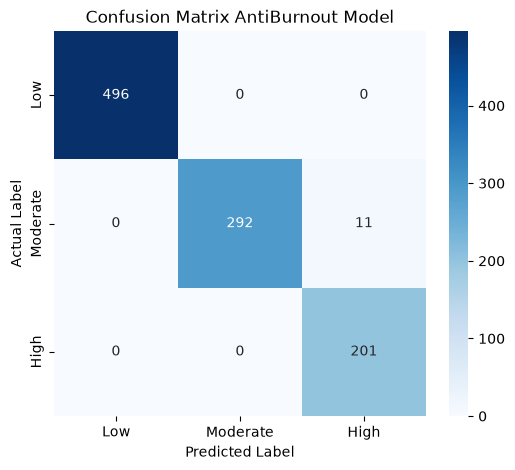

In [5]:
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Akurasi Pengujian: {acc * 100:.2f}%\n")

target_names = ['Low', 'Moderate', 'High']
print("Laporan Klasifikasi:")
print(classification_report(y_test, y_pred, target_names=target_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix AntiBurnout Model')
plt.show()

## Langkah 6: Menyimpan Artefak Model dan Scaler

In [6]:
os.makedirs('antiburnout-project', exist_ok=True)

# 1. Simpan model
with open('antiburnout-project/burnout_model.pkl', 'wb') as f:
    pickle.dump(model, f)
print("Model berhasil disimpan ke: antiburnout-project/burnout_model.pkl")

# 2. Simpan scaler
with open('antiburnout-project/burnout_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("Scaler berhasil disimpan ke: antiburnout-project/burnout_scaler.pkl")

# 3. Simpan nilai rata-rata fitur dan daftar nama fitur untuk inferensi
metadata = {
    'feature_names': selected_columns,
    'feature_means': feature_means.to_dict(),
    'encoding_maps': encoding_maps,
    'target_mapping': target_mapping,
    'target_labels': target_names
}
with open('antiburnout-project/burnout_metadata.pkl', 'wb') as f:
    pickle.dump(metadata, f)
print("Metadata berhasil disimpan ke: antiburnout-project/burnout_metadata.pkl")

Model berhasil disimpan ke: antiburnout-project/burnout_model.pkl
Scaler berhasil disimpan ke: antiburnout-project/burnout_scaler.pkl
Metadata berhasil disimpan ke: antiburnout-project/burnout_metadata.pkl


Model Gaussian Naive Bayes berhasil dilatih pada data AntiBurnout dengan performa akurasi pengujian mencapai 98.90%. Seluruh artefak yang diperlukan untuk proses inferensi real-time (model, scaler, dan metadata imputasi fitur) telah diekspor ke folder antiburnout-project. Folder tersebut kemudian dikonfigurasikan dengan web server Flask (app.py), dependencies (requirements.txt), dan container Docker (Dockerfile) untuk dideploy ke Hugging Face Spaces.